In [ ]:
import zipfile
import os

# Create the dataset directory if it doesn't exist
output_dir = "./dataset"
os.makedirs(output_dir, exist_ok=True)

# List of zip files to extract
zip_files = ["perruche.zip", "pas_perruche.zip"]

for zip_file in zip_files:
    if os.path.exists(zip_file):
        with zipfile.ZipFile(zip_file, 'r') as zip_ref:
            # Extract all the contents into the specified output directory
            zip_ref.extractall(output_dir)
        print(f"Extracted {zip_file} to {output_dir}")
    else:
        print(f"Warning: {zip_file} not found. Skipping extraction.")


Extracted perruche.zip to ./dataset
Extracted pas_perruche.zip to ./dataset


In [1]:
from pathlib import Path
import shutil
from sklearn.model_selection import train_test_split

# Dossiers source
POS_DIR = Path("./dataset/perruche")
NEG_DIR = Path("./dataset/pas_perruche")

# Dossier de sortie
OUT_DIR = Path("./dataset_split")

# Ratios
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

SEED = 42
IMG_EXTS = {".jpg", ".jpeg", ".png", ".webp"}

def get_images(folder):
    return [p for p in folder.iterdir() if p.suffix.lower() in IMG_EXTS]

def split_files(files):
    train, temp = train_test_split(
        files,
        train_size=TRAIN_RATIO,
        random_state=SEED,
        shuffle=True
    )

    val_ratio_adjusted = VAL_RATIO / (VAL_RATIO + TEST_RATIO)

    val, test = train_test_split(
        temp,
        train_size=val_ratio_adjusted,
        random_state=SEED,
        shuffle=True
    )

    return train, val, test

def copy_files(files, split_name, class_name):
    target_dir = OUT_DIR / split_name / class_name
    target_dir.mkdir(parents=True, exist_ok=True)

    for file in files:
        shutil.copy2(file, target_dir / file.name)

classes = {
    "perruche": POS_DIR,
    "pas_perruche": NEG_DIR
}

for class_name, folder in classes.items():
    files = get_images(folder)

    train_files, val_files, test_files = split_files(files)

    copy_files(train_files, "train", class_name)
    copy_files(val_files, "val", class_name)
    copy_files(test_files, "test", class_name)

    print(f"{class_name}:")
    print(f"  train: {len(train_files)}")
    print(f"  val:   {len(val_files)}")
    print(f"  test:  {len(test_files)}")

print("Dataset prêt.")

perruche:
  train: 1099
  val:   236
  test:  236
pas_perruche:
  train: 2100
  val:   450
  test:  450
Dataset prêt.


In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models
from pathlib import Path

# ==========================
# PARAMÈTRES
# ==========================

# Point to the directory created by the data splitting script
DATASET_SPLIT_PATH = "dataset_split"

IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
SEED = 42

# ==========================
# CHARGEMENT DES DATASETS SPLITTÉS
# ==========================

# Load training dataset
train_dataset = tf.keras.utils.image_dataset_from_directory(
    Path(DATASET_SPLIT_PATH) / "train",
    labels="inferred",
    label_mode="binary",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

# Load validation dataset
val_dataset = tf.keras.utils.image_dataset_from_directory(
    Path(DATASET_SPLIT_PATH) / "val",
    labels="inferred",
    label_mode="binary",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=False # No need to shuffle validation data
)

# Load test dataset
test_dataset = tf.keras.utils.image_dataset_from_directory(
    Path(DATASET_SPLIT_PATH) / "test",
    labels="inferred",
    label_mode="binary",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=False # No need to shuffle test data
)

# Affichage des classes détectées (assuming all datasets have the same classes)
print("Classes :", train_dataset.class_names)

# ==========================
# OPTIMISATION DES PERFORMANCES
# ==========================

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

# ==========================
# VÉRIFICATION
# ==========================

print("\nDatasets prêts !")
print(f"Train batches : {len(train_dataset)}")
print(f"Validation batches : {len(val_dataset)}")
print(f"Test batches : {len(test_dataset)}")


Found 3199 files belonging to 2 classes.
Found 686 files belonging to 2 classes.
Found 686 files belonging to 2 classes.
Classes : ['pas_perruche', 'perruche']

Datasets prêts !
Train batches : 100
Validation batches : 22
Test batches : 22


In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models

IMG_HEIGHT = 128
IMG_WIDTH = 128

model = models.Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),

    # Normalisation gardée dans le modèle
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    # Beaucoup plus léger que Flatten()
    layers.GlobalAveragePooling2D(),

    layers.Dense(32, activation="relu"),

    # 2 classes pour Edge Impulse Classification
    layers.Dense(2, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 97,442 (380.63 KB)

 Trainable params: 97,442 (380.63 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20
)

Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 109s 1s/step - accuracy: 0.6946 - loss: 0.6156 - val_accuracy: 0.6939 - val_loss: 0.6241
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 133s 994ms/step - accuracy: 0.7484 - loss: 0.5347 - val_accuracy: 0.7332 - val_loss: 0.5226
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 100s 992ms/step - accuracy: 0.8234 - loss: 0.4069 - val_accuracy: 0.8265 - val_loss: 0.3928
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 97s 976ms/step - accuracy: 0.8540 - loss: 0.3452 - val_accuracy: 0.8834 - val_loss: 0.3156
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 98s 979ms/step - accuracy: 0.8853 - loss: 0.3055 - val_accuracy: 0.8892 - val_loss: 0.3058
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 99s 993ms/step - accuracy: 0.9009 - loss: 0.2657 - val_accuracy: 0.8776 - val_loss: 0.3389
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 97s 970ms/step - accuracy: 0.9175 - loss: 0.2294 - val_accuracy: 0.9140 - val_loss: 0.2378
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 98s 978ms/step - accuracy: 0.9256 - loss: 0

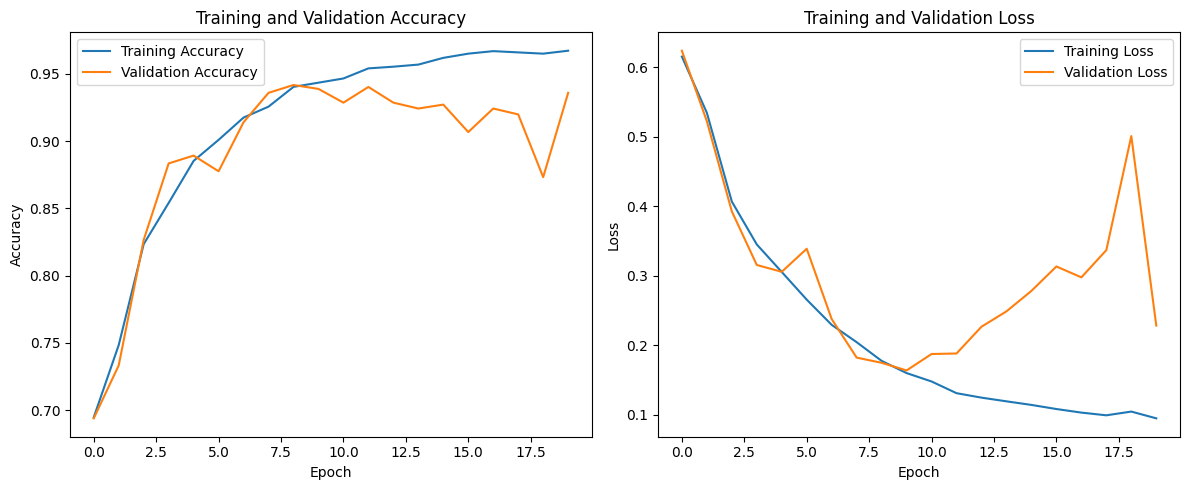

22/22 ━━━━━━━━━━━━━━━━━━━━ 9s 373ms/step - accuracy: 0.9402 - loss: 0.2026
Accuracy test : 0.9402
Loss test : 0.2026


In [5]:
import matplotlib.pyplot as plt

# Plot training history
hist = history.history
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(hist['accuracy'], label='Training Accuracy')
plt.plot(hist['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist['loss'], label='Training Loss')
plt.plot(hist['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# Evaluate on test set
loss, accuracy = model.evaluate(test_dataset)

print(f"Accuracy test : {accuracy:.4f}")
print(f"Loss test : {loss:.4f}")


In [6]:
import tensorflow as tf

# Save the model in SavedModel format
model_path = "./my_bird_model_V2"
model.export(model_path)
print(f"Model saved to: {model_path}")

# Convert the Keras model to TensorFlow Lite format
converter = tf.lite.TFLiteConverter.from_saved_model(model_path)
tflite_model = converter.convert()

# Save the TFLite model to a file
tflite_model_path = "./my_bird_model_V2.tflite"
with open(tflite_model_path, "wb") as f:
    f.write(tflite_model)

print(f"TensorFlow Lite model saved to: {tflite_model_path}")

Saved artifact at './my_bird_model_V2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  136123922929552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136123922931664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136123922931472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136123922931856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136123922932432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136123922930320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136123922932624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136123922932048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136123922929744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136123922933008: TensorSpec(shape=(), dtype=tf.resource, name=None)
Model saved to

In [7]:
import tensorflow as tf
import shutil
import os
import zipfile

# 1. Supprimer anciens exports
shutil.rmtree("my_bird_model_V2", ignore_errors=True)
if os.path.exists("my_bird_model_V2.zip"):
    os.remove("my_bird_model_V2.zip")

# 2. Export SavedModel propre
tf.saved_model.save(model, "my_bird_model_V2")

# 3. Vérifier contenu
print(os.listdir("my_bird_model_V2"))

['saved_model.pb', 'fingerprint.pb', 'variables', 'assets']


In [8]:
shutil.make_archive(
    "my_bird_model_V2",
    "zip",
    "my_bird_model_V2"
)

'/content/my_bird_model_V2.zip'